# Braude College of Engineering - Data Mining & Machine Learning (61761)
# Lab 2: Text Preprocessing, K-Nearest Neighbors (KNN) & Model Evaluation

In [28]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score, roc_curve
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier

### 2. Dataset Loading (Text Sentiment / Spam Sample)

In [29]:
# Sample text corpus representing customer feedback
sample_data = {
    "text": [
        "Great service, fast delivery and very friendly staff",
        "Terrible experience, arrived damaged and very late",
        "Awesome quality, exceeded all my expectations",
        "Poor customer support, refused to give a refund",
        "Loved the product, works like a charm every day",
        "Waste of money, completely broken on arrival",
        "Highly recommended, will definitely buy again soon",
        "Worst purchase ever, do not recommend to anyone",
        "Super happy with the performance and compact design",
        "Horrible smell, poor material and extremely cheap quality",
        "Excellent craftsmanship and fast responsive support",
        "Very disappointed, stop working after just two days",
        "Best deal online, reasonable price and good shipping",
        "Defective unit, customer representative was rude",
        "Impressed with the battery life and sharp screen",
        "Never buying again, totally unsatisfied with order",
        "Five stars, reliable device and beautiful color",
        "Bad quality, broke during first usage unfortunately",
        "Top notch customer care, resolved my issue quickly",
        "Do not buy, low grade plastic and missing accessories",
        "Outstanding product, very easy setup and use",
        "Awful packaging, item crushed inside the box",
        "Wonderful experience from ordering to unboxing",
        "Failed immediately, return process is a nightmare"
    ],
    "label": [1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0]
}
df = pd.DataFrame(sample_data)
display(df.head())
print("Class distribution:\n", df["label"].value_counts())

,text,label
0,"Great service, fast delivery and very friendly...",1
1,"Terrible experience, arrived damaged and very ...",0
2,"Awesome quality, exceeded all my expectations",1
3,"Poor customer support, refused to give a refund",0
4,"Loved the product, works like a charm every day",1


Class distribution:
 label
1    12
0    12
Name: count, dtype: int64


### 3. Bag-of-Words Representation & Stratified Split

In [30]:
# Bag-of-Words with standard English stop words removed
vectorizer = CountVectorizer(stop_words="english")
X_bow = vectorizer.fit_transform(df["text"])
y = df["label"]

print(f"Vocabulary size (with stop words removed): {len(vectorizer.vocabulary_)}")

# Stratified 75% Train / 25% Test split
X_train, X_test, y_train, y_test = train_test_split(
    X_bow, y, test_size=0.25, random_state=42, stratify=y
)
print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

Vocabulary size (with stop words removed): 114
Train shape: (18, 114), Test shape: (6, 114)


### 4. Baseline KNN Model & Accuracy Evaluation (Demo)

In [31]:
knn_demo = KNeighborsClassifier(n_neighbors=5)
knn_demo.fit(X_train, y_train)

y_pred_demo = knn_demo.predict(X_test)
acc_demo = accuracy_score(y_test, y_pred_demo)
print(f"Baseline KNN (K=5) Test Accuracy: {acc_demo:.4f}")

Baseline KNN (K=5) Test Accuracy: 0.5000


### 5. ROC Curve Demo

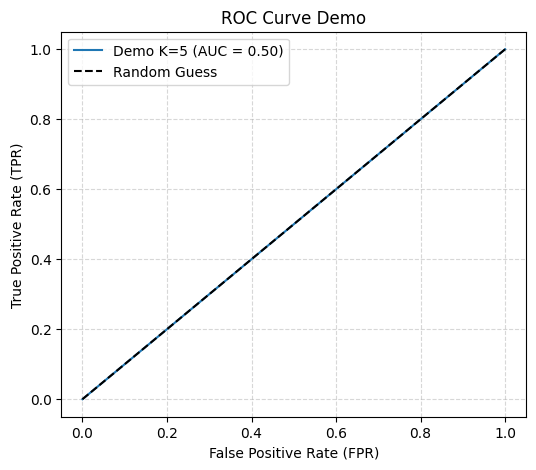

In [32]:
y_probs_demo = knn_demo.predict_proba(X_test)[:, 1]
fpr_demo, tpr_demo, _ = roc_curve(y_test, y_probs_demo)
auc_demo = roc_auc_score(y_test, y_probs_demo)

plt.figure(figsize=(6, 5))
plt.plot(fpr_demo, tpr_demo, label=f"Demo K=5 (AUC = {auc_demo:.2f})")
plt.plot([0, 1], [0, 1], "k--", label="Random Guess")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC Curve Demo")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

### 6. Hyperparameter Loop (K values) & Cross-Validation Demo

In [33]:
# Demonstration of checking multiple K values
k_candidates = [1, 3, 5]
for k in k_candidates:
    clf = KNeighborsClassifier(n_neighbors=k)
    clf.fit(X_train, y_train)
    train_acc = accuracy_score(y_train, clf.predict(X_train))
    test_acc = accuracy_score(y_test, clf.predict(X_test))
    print(f"K={k:2d} -> Train Accuracy: {train_acc:.4f} | Test Accuracy: {test_acc:.4f}")

K= 1 -> Train Accuracy: 1.0000 | Test Accuracy: 0.5000
K= 3 -> Train Accuracy: 0.7778 | Test Accuracy: 0.3333
K= 5 -> Train Accuracy: 0.5556 | Test Accuracy: 0.5000


In [34]:
# Demonstration of 5-Fold Cross-Validation
cv_scores = cross_val_score(knn_demo, X_train, y_train, cv=5, scoring="accuracy")
print(f"\n5-Fold CV Accuracy for K=5: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")


5-Fold CV Accuracy for K=5: 0.5000 (+/- 0.1054)


## PART B: Independent Student Tasks

### Task 1: Stop Words Impact on Vocabulary Size
1. Instantiate a new `CountVectorizer` with `stop_words=None` and fit it on `df['text']`.
2. Print the vocabulary size with and without stop words.
3. State the difference in feature dimensions.

In [35]:
# TODO 1.1: Build vectorizer with stop_words=None and check vocabulary size
vec_no_stop = CountVectorizer(stop_words=None)
vec_no_stop.fit(df["text"])

VNS = vec_no_stop.transform(df["text"])
print("Matrix shape (reviews x words):", VNS.shape)   # (24, 141)

bow_df = pd.DataFrame(VNS.toarray(), columns=vec_no_stop.get_feature_names_out())
pd.set_option("display.max_columns", None)
display(bow_df.head())

size_with_removal = len(vectorizer.vocabulary_)      # stop words removed
size_without_removal = len(vec_no_stop.vocabulary_)  # stop words kept

print(f"Vocabulary size WITH stop-word removal:    {size_with_removal}")
print(f"Vocabulary size WITHOUT stop-word removal: {size_without_removal}")
print(f"Exact difference: {size_without_removal - size_with_removal}")

Matrix shape (reviews x words): (24, 141)


,accessories,after,again,all,and,anyone,arrival,arrived,awesome,awful,bad,battery,beautiful,best,box,broke,broken,buy,buying,care,charm,cheap,color,compact,completely,craftsmanship,crushed,customer,damaged,day,days,deal,defective,definitely,delivery,design,device,disappointed,do,during,easy,ever,every,exceeded,excellent,expectations,experience,extremely,failed,fast,first,five,friendly,from,give,good,grade,great,happy,highly,horrible,immediately,impressed,inside,is,issue,item,just,late,life,like,loved,low,material,missing,money,my,never,nightmare,not,notch,of,on,online,order,ordering,outstanding,packaging,performance,plastic,poor,price,process,product,purchase,quality,quickly,reasonable,recommend,recommended,refund,refused,reliable,representative,resolved,responsive,return,rude,screen,service,setup,sharp,shipping,smell,soon,staff,stars,stop,super,support,terrible,the,to,top,totally,two,unboxing,unfortunately,unit,unsatisfied,usage,use,very,was,waste,will,with,wonderful,working,works,worst
0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
1,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
2,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0


Vocabulary size WITH stop-word removal:    114
Vocabulary size WITHOUT stop-word removal: 141
Exact difference: 27


### Task 2: Extended Evaluation Metrics for Baseline Model
1. Generate predictions on `X_test` using the baseline model `knn_demo` (K=5).
2. Display the Confusion Matrix.
3. Compute and print Precision, Recall, and F1-score formatted to 4 decimal places.

In [36]:
# TODO 2.1: Confusion matrix and detailed classification metrics (Precision, Recall, F1)
# TODO 2.1: Confusion matrix and detailed classification metrics (Precision, Recall, F1)
y_pred = knn_demo.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix (rows = actual, cols = predicted):")
print(cm)

display(pd.DataFrame(cm,
                     index=["Actual 0 (neg)", "Actual 1 (pos)"],
                     columns=["Pred 0 (neg)", "Pred 1 (pos)"]))

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred):.4f}")

Confusion Matrix (rows = actual, cols = predicted):
[[0 3]
 [0 3]]


,Pred 0 (neg),Pred 1 (pos)
Actual 0 (neg),0,3
Actual 1 (pos),0,3


TN=0, FP=3, FN=0, TP=3
Precision: 0.5000
Recall:    1.0000
F1-score:  0.6667


### Task 3: Hyperparameter Tuning & Overfitting Inspection
1. Iterate over K values: `[1, 3, 5, 9, 17, 33]` (handle cases where K exceeds training samples gracefully).
2. Print a table of Train Accuracy vs. Test Accuracy for each K.
3. Identify which K yields the highest Test Accuracy, and explain the behavior at K=1.

In [37]:
# TODO 3.1: Iterate over K values and display the comparison table
k_values = [1, 3, 5, 9, 17, 33]
n_train = X_train.shape[0]
results = []

for k in k_values:
    if k > n_train:
        print(f"K={k} skipped: exceeds number of training samples ({n_train})")
        continue
    clf = KNeighborsClassifier(n_neighbors=k)
    clf.fit(X_train, y_train)
    results.append({
        "K": k,
        "Train Accuracy": accuracy_score(y_train, clf.predict(X_train)),
        "Test Accuracy": accuracy_score(y_test, clf.predict(X_test)),
    })

results_df = pd.DataFrame(results).round(4)
display(results_df)

best_k = int(results_df.loc[results_df["Test Accuracy"].idxmax(), "K"])
print("Best K (highest Test Accuracy):", best_k)

K=33 skipped: exceeds number of training samples (18)


,K,Train Accuracy,Test Accuracy
0,1,1.0000,0.5000
1,3,0.7778,0.3333
2,5,0.5556,0.5000
3,9,0.6667,0.5000
4,17,0.5556,0.5000


Best K (highest Test Accuracy): 1


**Observation for Task 3:**  
*Best K value:*  
*Behavior observed at K=1 (Overfitting explanation):*

**Observation for Task 3:**

*Best K value:* K = 5. Test Accuracy is 0.5000 for K = 1, 5, 9 and 17, so the
test set alone cannot separate them (it contains only 6 samples; one error
changes accuracy by 0.1667). K = 1 is rejected because it overfits. Among the
remaining candidates, K = 5 has the smallest gap between Train Accuracy
(0.5556) and Test Accuracy (0.5000), i.e. 0.0556 (tied with K = 17), versus
0.1667 for K = 9, so it is the most stable choice and is chosen as the
tie-break. Note that 0.5000 equals random guessing, so no K performs well on
this tiny dataset.

*Behavior observed at K=1 (Overfitting explanation):* Train Accuracy is 1.0000
while Test Accuracy is only 0.5000. With K=1 every training point is its own
nearest neighbor, so the model simply memorizes the training set and gets
every training sample right. It fits noise instead of learning a general
pattern, which is why it fails on unseen reviews. Larger K averages over more
neighbors, smoothing the decision and reducing this memorization.

In [38]:
best_k = 5   # chosen manually, see Observation (ties on Test Accuracy)

### Task 4: Stratified Cross-Validation on Optimal K
1. Using your optimal K from Task 3, configure a KNN classifier.
2. Execute a 5-Fold Cross-Validation on `X_train` and `y_train` using `scoring='f1'`.
3. Print the individual fold scores, the mean F1 score, and the standard deviation.

In [39]:
# TODO 4.1: Perform 5-fold CV with F1 scoring on the optimal K model
from sklearn.model_selection import StratifiedKFold

knn_best = KNeighborsClassifier(n_neighbors=best_k)   # best_k = 5
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_f1 = cross_val_score(knn_best, X_train, y_train, cv=skf, scoring="f1")

print("5-Fold F1 scores:", np.round(cv_f1, 4))
print(f"Mean F1: {cv_f1.mean():.4f}")
print(f"Std  F1: {cv_f1.std():.4f}")

5-Fold F1 scores: [0.     0.5    0.6667 0.6667 0.8   ]
Mean F1: 0.5267
Std  F1: 0.2800


### Task 5: Comparative ROC Curves
1. Compute prediction probabilities (`predict_proba`) for K=1 and your optimal K.
2. Plot both ROC curves on the same chart, including labels with their respective AUC scores.
3. Explain which model is preferable and why.

K=1: AUC = 0.5000
K=5: AUC = 0.5000


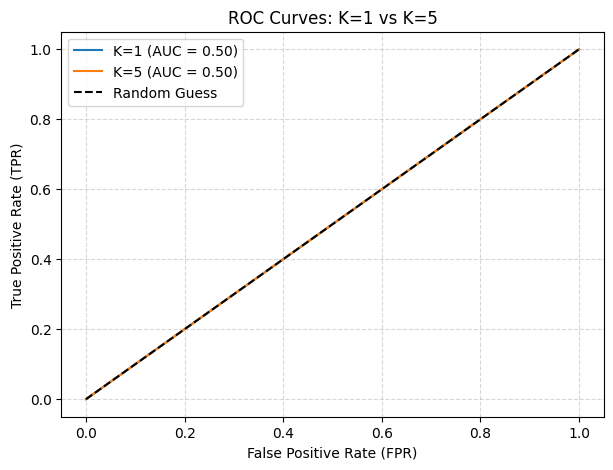

In [40]:
# TODO 5.1: Plot comparative ROC curves and print AUC values
plt.figure(figsize=(7, 5))

for k in [1, best_k]:
    clf = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    probs = clf.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc = roc_auc_score(y_test, probs)
    print(f"K={k}: AUC = {auc:.4f}")
    plt.plot(fpr, tpr, label=f"K={k} (AUC = {auc:.2f})")

plt.plot([0, 1], [0, 1], "k--", label="Random Guess")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.title("ROC Curves: K=1 vs K=%d" % best_k)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

**Conclusion (Task 5):** Neither model generalizes: both have AUC = 0.5000
(K=1 and K=5), i.e. exactly random guessing, and their ROC curves lie on the
diagonal. K=1 overfits (Train accuracy 1.0) and outputs only 0/1
probabilities. K=5 averages over more neighbors and outputs graded
probabilities (0.6 / 0.8), but these do not separate the classes, so its
ranking is no better than chance. The test set has only 6 samples, so no
reliable difference can be claimed. If a choice must be made, K=5 is
preferable in principle (lower variance, smaller Train-Test gap), but this
data does not demonstrate it. More data is needed for a reliable comparison.